# Raw data inspection

Explore `01_data/raw` without modifying the source files. Metadata covers every Parquet row; broad profiles use **the first 5,000 rows**, so they are not random or representative estimates. Full-data checks read only selected columns.

Requires Python, pandas, pyarrow, matplotlib, and a Jupyter kernel. The repository's `requirements.txt` contains the data libraries; install `jupyter` or use your editor's notebook support to run this file.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from the repository root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "01_data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the repository.")
RAW = ROOT / "01_data" / "raw"
SAMPLE_ROWS = 5_000
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
print(f"Inspecting: {RAW}")

Inspecting: C:\Users\tonyt\Documents\hackathonfiam_zzz\01_data\raw


## 1. File inventory and dataset schemas

In [2]:
files = sorted(p for p in RAW.rglob("*") if p.is_file())
display(pd.DataFrame([{
    "file": str(p.relative_to(RAW)), "format": p.suffix,
    "size_MiB": round(p.stat().st_size / 1024**2, 2)
} for p in files]))
parquets = {p.stem: pq.ParquetFile(p) for p in files if p.suffix == ".parquet"}
display(pd.DataFrame([{
    "dataset": name, "rows": pf.metadata.num_rows,
    "columns": len(pf.schema_arrow), "row_groups": pf.num_row_groups
} for name, pf in parquets.items()]))
for name, pf in parquets.items():
    print(f"\n{name}")
    display(pd.DataFrame([{"column": f.name, "arrow_type": str(f.type),
                           "nullable": f.nullable} for f in pf.schema_arrow]))

,file,format,size_MiB
0,8k_20150101_20260831_identified.parquet,.parquet,341.49
1,chars_final_with_names.parquet,.parquet,393.49
2,external\ff3.zip,.zip,0.01
3,external\SP500_fred.csv,.csv,0.05
4,external\TB3MS.csv,.csv,0.02
5,factor_char_list.csv,.csv,0.00
6,readme.md,.md,0.03


,dataset,rows,columns,row_groups
0,8k_20150101_20260831_identified,373139,94,93
1,chars_final_with_names,529082,198,33



8k_20150101_20260831_identified


,column,arrow_type,nullable
0,document_id,string,True
1,company_name,string,True
2,ticker,string,True
3,exchange,string,True
4,figi,string,True
...,...,...,...
89,duplicate_source_document_ids,list<element: string>,True
90,gvkey_iid,string,True
91,cusip8,string,True
92,cusip_date_precision,string,True



chars_final_with_names


,column,arrow_type,nullable
0,id,int64,True
1,permno,int64,True
2,permco,int64,True
3,gvkey,large_string,True
4,iid,large_string,True
...,...,...,...
193,ticker,string,True
194,company_name,string,True
195,ticker_name_reference_date,date32[day],True
196,ticker_name_source,string,True


## 2. Bounded previews and missing values
Missing percentages and numeric summaries below describe only the first 5,000 rows. Long text is truncated for display; nested fields retain their Arrow-derived values.

In [3]:
samples = {}
for name, pf in parquets.items():
    batch = next(pf.iter_batches(batch_size=SAMPLE_ROWS), None)
    df = batch.to_pandas() if batch is not None else pd.DataFrame(columns=pf.schema_arrow.names)
    samples[name] = df
    print(f"\n{name}: first {len(df):,} rows")
    display(df.head(5))
    profile = pd.DataFrame({"dtype": df.dtypes.astype(str),
                            "missing_rows": df.isna().sum(),
                            "missing_pct": df.isna().mean().mul(100).round(2)})
    display(profile.sort_values("missing_pct", ascending=False))
    display(df.describe(include="number").T)


8k_20150101_20260831_identified: first 5,000 rows


,document_id,company_name,ticker,exchange,figi,composite_figi,share_class_figi,cik,cusip,isin,accession_number,sector,industry,country,region,...,ticker_source,company_name_source,compustat_header_cusip,compustat_header_cik,compustat_header_ticker,compustat_header_company_name,openfigi_mapping_cusips,identifier_mapping_sources,identifier_quality_flags,identifier_source_row,duplicate_source_document_ids,gvkey_iid,cusip8,cusip_date_precision,identifiers_processed_at_utc
0,MF-CR-20151116-USPH-UN,U S PHYSICAL THERAPY INC /NV,USPH,UN,BBG000CSRV60,BBG000CSRSG6,BBG001S71ZL9,0000885978,90337L108,None,None,HealthServices,MedicalOrNursingServices,United States,North America,...,CRSP_monthly_trading_symbol,SEC_issuer_name_history_at_filing_date,90337L108,0000885978,USPH,US PHYSICAL THERAPY INC,[90337L108],"[CRSP_CUSIP9_to_OpenFIGI, Compustat_header_CUSIP_to_OpenFIGI_via_characteristics]",[],0,[MF-CR-20151116-USPH-UN],025318-01,90337L10,monthly_snapshot,2026-09-08 09:27:09.459689+00:00
1,MF-CR-20151106-USPH-UN,U S PHYSICAL THERAPY INC /NV,USPH,UN,BBG000CSRV60,BBG000CSRSG6,BBG001S71ZL9,0000885978,90337L108,None,None,HealthServices,MedicalOrNursingServices,United States,North America,...,CRSP_monthly_trading_symbol,SEC_issuer_name_history_at_filing_date,90337L108,0000885978,USPH,US PHYSICAL THERAPY INC,[90337L108],"[CRSP_CUSIP9_to_OpenFIGI, Compustat_header_CUSIP_to_OpenFIGI_via_characteristics]",[],1,[MF-CR-20151106-USPH-UN],025318-01,90337L10,monthly_snapshot,2026-09-08 09:27:09.459689+00:00
2,MF-CR-20150701-USPH-UN,U S PHYSICAL THERAPY INC /NV,USPH,UN,BBG000CSRV60,BBG000CSRSG6,BBG001S71ZL9,0000885978,90337L108,None,None,HealthServices,MedicalOrNursingServices,United States,North America,...,CRSP_monthly_trading_symbol,SEC_issuer_name_history_at_filing_date,90337L108,0000885978,USPH,US PHYSICAL THERAPY INC,[90337L108],"[CRSP_CUSIP9_to_OpenFIGI, Compustat_header_CUSIP_to_OpenFIGI_via_characteristics]",[],2,[MF-CR-20150701-USPH-UN],025318-01,90337L10,monthly_snapshot,2026-09-08 09:27:09.459689+00:00
3,MF-CR-20150519-USPH-UN,U S PHYSICAL THERAPY INC /NV,USPH,UN,BBG000CSRV60,BBG000CSRSG6,BBG001S71ZL9,0000885978,90337L108,None,None,HealthServices,MedicalOrNursingServices,United States,North America,...,CRSP_monthly_trading_symbol,SEC_issuer_name_history_at_filing_date,90337L108,0000885978,USPH,US PHYSICAL THERAPY INC,[90337L108],"[CRSP_CUSIP9_to_OpenFIGI, Compustat_header_CUSIP_to_OpenFIGI_via_characteristics]",[],3,[MF-CR-20150519-USPH-UN],025318-01,90337L10,monthly_snapshot,2026-09-08 09:27:09.459689+00:00
4,MF-CR-20150831-USPH-UN,U S PHYSICAL THERAPY INC /NV,USPH,UN,BBG000CSRV60,BBG000CSRSG6,BBG001S71ZL9,0000885978,90337L108,None,None,HealthServices,MedicalOrNursingServices,United States,North America,...,CRSP_monthly_trading_symbol,SEC_issuer_name_history_at_filing_date,90337L108,0000885978,USPH,US PHYSICAL THERAPY INC,[90337L108],"[CRSP_CUSIP9_to_OpenFIGI, Compustat_header_CUSIP_to_OpenFIGI_via_characteristics]",[],4,[MF-CR-20150831-USPH-UN],025318-01,90337L10,monthly_snapshot,2026-09-08 09:27:09.459689+00:00


,dtype,missing_rows,missing_pct
accession_number,object,5000,100.00
isin,object,5000,100.00
sec_accepted_at_utc,"datetime64[us, UTC]",5000,100.00
provider_added_at_utc,"datetime64[us, UTC]",5000,100.00
title,object,307,6.14
...,...,...,...
duplicate_source_document_ids,object,0,0.00
gvkey_iid,object,0,0.00
cusip8,object,0,0.00
cusip_date_precision,object,0,0.00


,count,mean,std,min,25%,50%,75%,max
archive_year,5000.0,2015.000000,0.000000,2015.0,2015.00,2015.0,2015.00,2015.0
text_chars,5000.0,4316.514200,3666.031539,1672.0,2565.75,3132.0,4700.25,77542.0
word_count,5000.0,657.795000,578.075036,253.0,387.00,474.0,714.00,13319.0
raw_text_chars,5000.0,4351.949800,3665.575806,1696.0,2601.75,3166.0,4735.25,77566.0
source_row_offset,5000.0,2087.058000,1456.164623,0.0,855.75,1669.0,3352.25,4999.0
removed_prefix_chars,5000.0,35.415800,14.071862,6.0,28.00,30.0,40.00,153.0
removed_metadata_chars,5000.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.0
days_filing_after_content_report,4987.0,1.624424,9.354128,-6.0,0.00,0.0,2.00,365.0
permno,5000.0,53188.602600,31024.443131,10104.0,17005.00,57904.0,84319.00,93372.0
permco,5000.0,30080.882000,18205.010848,90.0,20270.00,26048.0,51635.00,55480.0



chars_final_with_names: first 5,000 rows


,id,permno,permco,gvkey,iid,excntry,exch_main,common,primary_sec,bidask,primaryexch,conditionaltype,crsp_nyse,shrcd,exchcd,...,prc_highprc_252d,zero_trades_252d,betabab_1260d,rmax5_rvol_21d,age,qmj_prof,qmj_growth,qmj_safety,qmj,me_lag1,ticker,company_name,ticker_name_reference_date,ticker_name_source,ticker_name_status
0,10001,10001,7953,012994,01,USA,1,1,1,0,A,RW,0,11,2,...,0.740319,0.004815,0.369930,0.815597,349,-0.793438,-1.174184,-0.554461,-1.339223,115.57776,EGAS,GAS NATURAL INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
1,10025,10025,7975,011903,01,USA,1,1,1,0,Q,RW,0,11,3,...,0.861737,0.005562,1.323570,0.844325,361,-0.659718,-1.648672,-1.076800,-1.539792,295.46015,AEPI,A E P INDUSTRIES INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
2,10026,10026,7976,012825,01,USA,1,1,1,0,Q,RW,0,11,3,...,0.854481,0.007454,1.047745,1.501069,361,1.291849,-1.083642,1.560033,1.060720,2031.60606,JJSF,J & J SNACK FOODS CORP,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
3,10028,10028,7978,012096,01,USA,1,1,1,0,A,RW,0,11,2,...,0.555147,1.096408,0.577646,1.475714,361,0.288480,1.542084,-0.634534,0.691674,14.91328,DGSE,D G S E COMPANIES INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
4,10032,10032,7980,012945,01,USA,1,1,1,0,Q,RW,0,11,3,...,0.848981,0.005735,1.329622,0.695644,349,-0.891624,-0.555288,0.647570,-0.687090,1384.86205,PLXS,PLEXUS CORP,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month


,dtype,missing_rows,missing_pct
comp_tpci,object,5000,100.00
comp_exchg,float64,5000,100.00
rd5_at,float64,3096,61.92
rd_sale,float64,2483,49.66
rd_me,float64,2325,46.50
...,...,...,...
ret,float64,0,0.00
ret_local,float64,0,0.00
ret_exc,float64,0,0.00
age,int64,0,0.00


,count,mean,std,min,25%,50%,75%,max
id,5000.0,48210.027600,34048.531558,10001.000000,14185.000000,36142.000000,85424.750000,93436.000000
permno,5000.0,48210.027600,34048.531558,10001.000000,14185.000000,36142.000000,85424.750000,93436.000000
permco,5000.0,33215.605200,20020.805480,5.000000,13731.750000,37146.500000,53979.000000,58620.000000
exch_main,5000.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
common,5000.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...
qmj_prof,4957.0,-0.035166,1.004767,-1.731349,-0.910326,-0.039742,0.829907,1.731349
qmj_growth,3681.0,-0.000393,0.995106,-1.731191,-0.857859,-0.007450,0.854421,1.731203
qmj_safety,4982.0,-0.007264,1.003933,-1.731353,-0.874522,-0.007217,0.851244,1.731353
qmj,3681.0,0.004761,0.992398,-1.731191,-0.841814,0.001719,0.864736,1.731191


## 3. Full-data dates, identifiers, and duplicate keys
Read only the columns needed for these checks. Keep string identifiers such as GVKEY and IID as supplied. Multiple filings per security and day are valid; test the documented filing key.

In [4]:
filing_pf = parquets["8k_20150101_20260831_identified"]
chars_pf = parquets["chars_final_with_names"]
filings = filing_pf.read(columns=["document_id", "permno", "filing_date", "text_sha256",
                                  "form_type", "word_count", "text_chars"]).to_pandas()
chars = chars_pf.read(columns=["permno", "gvkey", "iid", "date", "eom"]).to_pandas()
checks = []
for name, df, date_col, keys in [
    ("filings", filings, "filing_date", ["permno", "filing_date", "text_sha256"]),
    ("characteristics", chars, "eom", ["permno", "eom"])
]:
    dates = pd.to_datetime(df[date_col])
    checks.append({"dataset": name, "rows": len(df), "securities": df.permno.nunique(),
                   "first_date": dates.min(), "last_date": dates.max(),
                   "rows_with_missing_key": int(df[keys].isna().any(axis=1).sum()),
                   "duplicate_key_rows_after_first": int(df.duplicated(keys).sum())})
display(pd.DataFrame(checks))
print("Duplicate document IDs:", filings.document_id.duplicated().sum())
print("Duplicate (gvkey, iid, eom):", chars.duplicated(["gvkey", "iid", "eom"]).sum())
display(filings.form_type.value_counts(dropna=False).rename("rows").to_frame())
display(filings[["word_count", "text_chars"]].describe(percentiles=[.5, .9, .99]).T)

,dataset,rows,securities,first_date,last_date,rows_with_missing_key,duplicate_key_rows_after_first
0,filings,373139,3687,2015-01-02,2026-08-31,0,0
1,characteristics,529082,6561,2015-01-31,2026-08-31,0,0


Duplicate document IDs: 0


Duplicate (gvkey, iid, eom): 0


,rows
form_type,
8-K,373054
8-K/A,85


,count,mean,std,min,50%,90%,99%,max
word_count,373139.0,786.217664,767.039210,173.0,595.0,1301.0,3204.00,183439.0
text_chars,373139.0,5088.842646,4926.364056,1139.0,3851.0,8424.0,20505.62,1163274.0


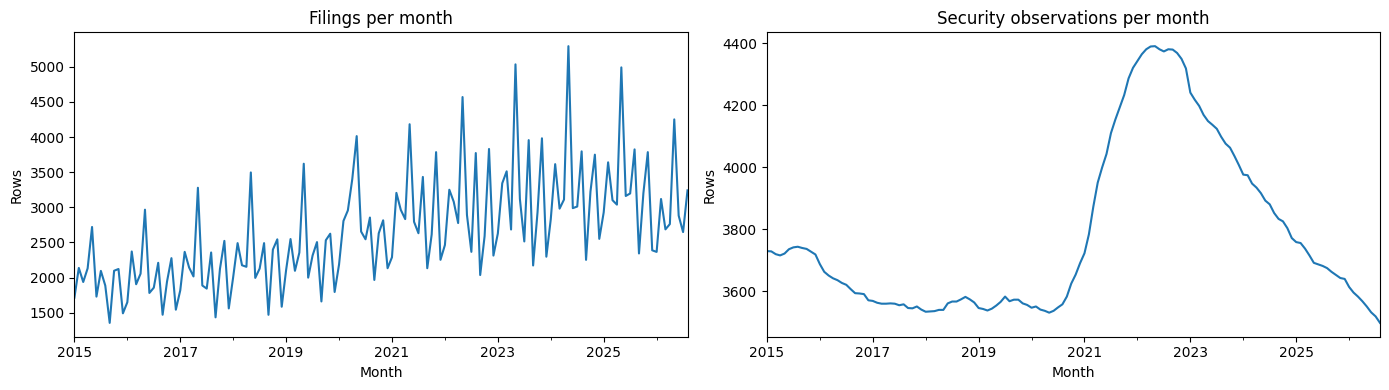

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, df, date_col, title in [
    (axes[0], filings, "filing_date", "Filings per month"),
    (axes[1], chars, "eom", "Security observations per month")
]:
    counts = pd.to_datetime(df[date_col]).dt.to_period("M").value_counts().sort_index()
    counts.index = counts.index.to_timestamp()
    counts.plot(ax=ax, title=title)
    ax.set_ylabel("Rows")
    ax.set_xlabel("Month")
plt.tight_layout()
plt.show()

## 4. Coverage between datasets
This checks security coverage and same-calendar-month availability only. It does not establish that information was available for a trading decision, or validate dated GVKEY/IID relationships.

In [6]:
filing_ids = set(filings.permno.dropna())
char_ids = set(chars.permno.dropna())
display(pd.Series({"securities in both": len(filing_ids & char_ids),
                   "filing-only securities": len(filing_ids - char_ids),
                   "characteristics-only securities": len(char_ids - filing_ids)}).to_frame("count"))
filing_months = pd.MultiIndex.from_arrays([
    filings.permno, pd.to_datetime(filings.filing_date).dt.to_period("M")])
char_months = pd.MultiIndex.from_arrays([
    chars.permno, pd.to_datetime(chars.eom).dt.to_period("M")])
has_month = filing_months.isin(char_months)
display(pd.Series({"filings with same-month panel row": int(has_month.sum()),
                   "filings without same-month panel row": int((~has_month).sum())}).to_frame("rows"))

,count
securities in both,3687
filing-only securities,0
characteristics-only securities,2874


,rows
filings with same-month panel row,370201
filings without same-month panel row,2938


## 5. Factor list and external reference files
CSV previews preserve source strings. ZIP members are listed without extraction; embedded provider files may contain header notes and need a format-specific parser.

In [7]:
factors = pd.read_csv(RAW / "factor_char_list.csv", dtype="string")
display(factors)
listed = factors["variable"].dropna().tolist()
print(f"Listed factors: {len(listed)}; unique: {len(set(listed))}")
print("Listed factors absent from characteristics:", sorted(set(listed) - set(chars_pf.schema_arrow.names)))
for p in files:
    if p.suffix.lower() == ".csv" and p.parent.name == "external":
        print(f"\n{p.name}")
        df = pd.read_csv(p, dtype="string")
        print(f"{len(df):,} rows × {len(df.columns)} columns")
        display(df.head())
        display(df.isna().sum().rename("missing_rows").to_frame())
    elif p.suffix.lower() == ".zip":
        print(f"\n{p.name}")
        with ZipFile(p) as z:
            display(pd.DataFrame([{"member": i.filename, "bytes": i.file_size}
                                  for i in z.infolist()]))
            for member in z.namelist():
                if member.lower().endswith((".csv", ".txt")):
                    with z.open(member) as stream:
                        print("".join(stream.readline().decode("utf-8-sig", errors="replace")
                                      for _ in range(12)))

,variable
0,age
1,aliq_at
2,aliq_mat
3,ami_126d
4,at_be
...,...
142,turnover_var_126d
143,z_score
144,zero_trades_126d
145,zero_trades_21d


Listed factors: 147; unique: 147
Listed factors absent from characteristics: []

ff3.zip


,member,bytes
0,F-F_Research_Data_Factors.csv,52453


This file was created using the 202607 CRSP database.
The 1-month TBill rate data until 202405 are from Ibbotson Associates. Starting from 202406, the 1-month TBill rate is from ICE BofA US 1-Month Treasury Bill Index. 
The annual TBill return is compounded from the monthly T-bill rates from January to December. 

,Mkt-RF,SMB,HML,RF
192607,   2.89,  -2.42,  -2.75,   0.22
192608,   2.64,  -1.44,   4.13,   0.25
192609,   0.38,  -1.36,   0.05,   0.23
192610,  -3.27,  -0.18,   0.78,   0.32
192611,   2.54,  -0.17,  -0.48,   0.31
192612,   2.62,  -0.06,   0.10,   0.28
192701,  -0.05,  -0.47,   4.76,   0.25


SP500_fred.csv
2,610 rows × 2 columns


,observation_date,SP500
0,2016-09-12,2159.04
1,2016-09-13,2127.02
2,2016-09-14,2125.77
3,2016-09-15,2147.26
4,2016-09-16,2139.16


,missing_rows
observation_date,0
SP500,96



TB3MS.csv
1,112 rows × 2 columns


,observation_date,TB3MS
0,1934-01-01,0.72
1,1934-02-01,0.62
2,1934-03-01,0.24
3,1934-04-01,0.15
4,1934-05-01,0.16


,missing_rows
observation_date,0
TB3MS,0


## Interpretation notes

Consult [the dataset guide](../01_data/raw/readme.md) before modeling.

- `ret_exc_lead1m` is a future return and must not be an input feature for that row's month.
- Filing timestamps have date-level or placeholder precision; do not infer intraday public availability.
- Tickers and company names are display labels. Use dated security identifiers for joins.
- Missingness in the bounded preview may differ substantially from full-data missingness. Empty schema placeholders and unavailable labels are documented in the guide.
- This notebook inspects sources in place and writes no derived data.